In [67]:
!pip install langchain langchain-groq langchain-community python-dotenv faiss-cpu pypdf


[notice] A new release of pip available: 22.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [68]:
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.tools import tool
from langgraph.graph import StateGraph,START,END
from typing import Annotated,TypedDict
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage,BaseMessage
from langgraph.prebuilt import tools_condition,ToolNode

In [69]:
load_dotenv()

True

In [70]:
import os
llm=ChatGroq(model="qwen/qwen3.8-27b",api_key=os.getenv("GROQ_API_KEY"),max_tokens=50)

In [71]:
!pip install pypdf
from langchain_community.document_loaders import PyPDFLoader 


[notice] A new release of pip available: 22.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [72]:
# load the document
loader=PyPDFLoader(r"C:\users\admin\OneDrive\Desktop\New folder\LangGraph\8_RAG\Ecommerce_Intern_Assignment_Glossary.pdf")

In [73]:
docs=loader.load()

In [74]:
len(docs)

9

In [75]:
splitter=RecursiveCharacterTextSplitter(chunk_size=150,chunk_overlap=40)
chunks=splitter.split_documents(docs)

In [76]:
len(chunks)

141

In [77]:
chunks

[Document(metadata={'producer': 'Microsoft® Word for Microsoft 365', 'creator': 'Microsoft® Word for Microsoft 365', 'creationdate': '2026-04-01T17:20:35+05:30', 'author': 'Un-named', 'moddate': '2026-04-01T17:20:35+05:30', 'source': 'C:\\users\\admin\\OneDrive\\Desktop\\New folder\\LangGraph\\8_RAG\\Ecommerce_Intern_Assignment_Glossary.pdf', 'total_pages': 9, 'page': 0, 'page_label': '1'}, page_content='Ecommerce Operations & Analyst Intern Assignment  |  Page 1 of 9 \nECOMMERCE OPERATIONS & ANALYST \nINTERN ASSIGNMENT \nMarch 2026 \n \nDOCUMENT INFO'),
 Document(metadata={'producer': 'Microsoft® Word for Microsoft 365', 'creator': 'Microsoft® Word for Microsoft 365', 'creationdate': '2026-04-01T17:20:35+05:30', 'author': 'Un-named', 'moddate': '2026-04-01T17:20:35+05:30', 'source': 'C:\\users\\admin\\OneDrive\\Desktop\\New folder\\LangGraph\\8_RAG\\Ecommerce_Intern_Assignment_Glossary.pdf', 'total_pages': 9, 'page': 0, 'page_label': '1'}, page_content='March 2026 \n \nDOCUMENT INFO  

In [78]:
!pip install langchain-huggingface


[notice] A new release of pip available: 22.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [79]:
from langchain_huggingface import ChatHuggingFace,HuggingFaceEmbeddings,HuggingFaceEndpoint

In [80]:
!pip install langchain-huggingface
!pip install sentence-transformers


[notice] A new release of pip available: 22.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip available: 22.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [81]:
import sys
!{sys.executable} -m pip install sentence-transformers

'c:\Users\Admin\OneDrive\Desktop\New' is not recognized as an internal or external command,
operable program or batch file.


In [82]:
import sys, subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "sentence-transformers", "transformers", "torch"
])

0

In [83]:
# Install once in your venv terminal:
# pip install sentence-transformers

from sentence_transformers import SentenceTransformer
import numpy as np

# Load model (downloads ~80MB once, then cached forever)
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

# Your texts
texts = [
    "A young wizard discovers he has magical powers.",
    "A boy attends a school for wizards and fights evil.",
    "A chef opens a restaurant in Paris."
]

# Create embeddings
embeddings = model.encode(texts, normalize_embeddings=True)

print("Shape:", embeddings.shape)   # (3, 384)
print("Vector 1:", embeddings[0][:5])  # first 5 numbers of first vector

ModuleNotFoundError: Could not import module 'PreTrainedModel'. Are this object's requirements defined correctly? Set the logging verbosity to DEBUG for the original import error.

In [84]:
# pip install -U langchain-cohere
from langchain_cohere import CohereEmbeddings

embeddings = CohereEmbeddings(model="embed-english-v3.0")

In [85]:
# from langchain_huggingface import HuggingFaceEmbeddings

# embedding_model = HuggingFaceEmbeddings(
#     model_name="sentence-transformers/all-MiniLM-L6-v2"
# )

In [87]:
from langchain_community.vectorstores import FAISS 
vector_store=FAISS.from_documents(chunks,embeddings)

In [88]:
vector_store

In [89]:
retriever=vector_store.as_retriever(search_type="similarity",search_kwargs={"k":4})

In [90]:
@tool
def rag_tool(query):
    """
    Retrieve relevant information from the pdf document.
    Use this tool when the user asks factual/conceptual questions that might be answered from the stored documents.
    """
    result=retriever.invoke(query)
    context=[doc.page_content for doc in result]
    metadata=[doc.metadata for doc in result]
    return {
        "query":query,
        "context":context,
        "metadata":metadata
    }
    

In [91]:
retriever.invoke("What is this doc all about?")

[Document(id='31951a43-be68-4e36-b340-66ad3c146f44', metadata={'producer': 'Microsoft® Word for Microsoft 365', 'creator': 'Microsoft® Word for Microsoft 365', 'creationdate': '2026-04-01T17:20:35+05:30', 'author': 'Un-named', 'moddate': '2026-04-01T17:20:35+05:30', 'source': 'C:\\users\\admin\\OneDrive\\Desktop\\New folder\\LangGraph\\8_RAG\\Ecommerce_Intern_Assignment_Glossary.pdf', 'total_pages': 9, 'page': 7, 'page_label': '8'}, page_content='teams, summarising findings and recommending specific actions.'),
 Document(id='8795808d-67a6-4e36-a857-9468fc594fab', metadata={'producer': 'Microsoft® Word for Microsoft 365', 'creator': 'Microsoft® Word for Microsoft 365', 'creationdate': '2026-04-01T17:20:35+05:30', 'author': 'Un-named', 'moddate': '2026-04-01T17:20:35+05:30', 'source': 'C:\\users\\admin\\OneDrive\\Desktop\\New folder\\LangGraph\\8_RAG\\Ecommerce_Intern_Assignment_Glossary.pdf', 'total_pages': 9, 'page': 1, 'page_label': '2'}, page_content='Important: \n• MH-LG-3301 has a 

In [92]:
tools=[rag_tool]
llm_with_tools=llm.bind_tools(tools)

In [96]:
class ChatState(TypedDict):
    messages:Annotated[list[BaseMessage],add_messages]

In [97]:
def chat_node(state: ChatState):
    messages=state["messages"]
    response=llm_with_tools.invoke(messages)
    return {
        "messages":[response]
    }

In [98]:
tool_node=ToolNode(tools)

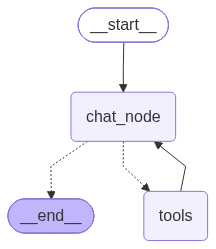

In [99]:
graph=StateGraph(ChatState)
graph.add_node("chat_node",chat_node)
graph.add_node("tools",tool_node)

graph.add_edge(START,"chat_node")
graph.add_conditional_edges("chat_node",tools_condition)
graph.add_edge("tools","chat_node")

chatbot=graph.compile()
chatbot

In [100]:
result=chatbot.invoke(
    {
        "messages":HumanMessage(content="What is task given? in 2 lines")
    }
)

In [101]:
print(result["messages"][-1].content)

Describe your immediate actions in the next 30 minutes, in order of priority.
Demonstrate real urgency, prioritisation, and acknowledged trade-offs.


In [102]:
# chat_node->tools->chat_node